# H1: the vertical feature in the PM-vs-Gaia plot (internal plots, not for the paper)

Slice 000, the 281k Gaia stars of the F7 selection. Table built by `py_files/pm_outliers.py` (see PLAN.md H1):
`combined/h1_gaia_stars_000.fits`. Outlier = |ours - Gaia| > 30 mas/yr.
"After fix" = refit without unmeasured epochs (full_fit_dra == 0) and with iterative 5-sigma epoch rejection.

In [1]:
import os, sys
import numpy as np, fitsio
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps
ps.apply()
OUT = 'plots/'
H = fitsio.read('/pscratch/sd/n/nelfalou/legacypm-catalogue/combined/h1_gaia_stars_000.fits')
G = H['gaia_phot_g_mean_mag']
out_cat = H['is_outlier'].astype(bool)
out_fix = H['is_outlier_after_fix'].astype(bool)
dpm_refit = np.hypot(H['refit_dpmra'], H['refit_dpmdec'])
bright = H['flag_bright'].astype(bool) | H['flag_saturated'].astype(bool)
short = H['flag_short_time'].astype(bool)
nocol = H['flag_no_colour'].astype(bool)
clean = (G > 16) & ~bright & ~short & ~nocol
# one primary cause per star, in this priority order
cause = np.where(short, 'short time coverage (< 10 epochs or < 2 yr)',
        np.where(bright, 'bright / saturated', np.where(nocol, 'no g-i colour (no DCR)', 'none of these')))
CAUSES = ['short time coverage (< 10 epochs or < 2 yr)', 'bright / saturated', 'no g-i colour (no DCR)', 'none of these']
print(len(H), 'stars;', out_cat.sum(), 'outliers;', {c: int((out_cat & (cause == c)).sum()) for c in CAUSES})

281160 stars; 11879 outliers; {'short time coverage (< 10 epochs or < 2 yr)': 7561, 'bright / saturated': 2444, 'no g-i colour (no DCR)': 715, 'none of these': 1159}


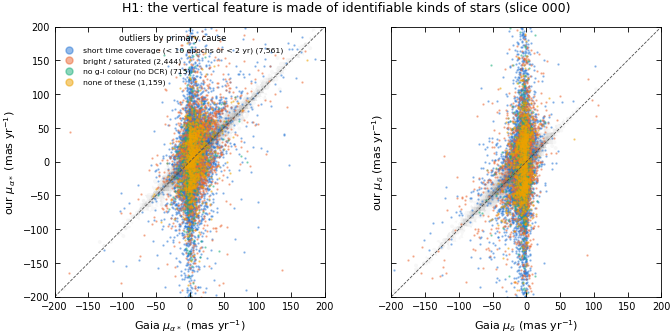

In [2]:
# 1. The stripe, coloured by the outliers' primary cause
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 3.4), sharex=True, sharey=True, constrained_layout=True)
lims = (-200, 200)
for ax, ours, gaia, name in [(axes[0], H['pmra_no_plx'], H['pmra'], r'\mu_{\alpha*}'), (axes[1], H['pmdec_no_plx'], H['pmdec'], r'\mu_\delta')]:
    ax.hexbin(gaia[~out_cat], ours[~out_cat], gridsize=120, extent=lims + lims, bins='log', cmap=ps.DENSITY, mincnt=1)
    for k, c in enumerate(CAUSES):
        s = out_cat & (cause == c)
        ax.scatter(gaia[s], ours[s], s=0.4, alpha=0.5, color=ps.SERIES[k], rasterized=True, label=f'{c} ({s.sum():,})')
    ax.plot(lims, lims, color='0.3', ls='--', lw=0.6)
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect('equal')
    ax.set_xlabel(f'Gaia ${name}$ (mas yr$^{{-1}}$)'); ax.set_ylabel(f'our ${name}$ (mas yr$^{{-1}}$)')
axes[0].legend(fontsize=5.5, markerscale=8, loc='upper left', title='outliers by primary cause', title_fontsize=6)
fig.suptitle('H1: the vertical feature is made of identifiable kinds of stars (slice 000)')
plt.savefig(OUT + 'h1_stripe_by_cause.png', dpi=200)

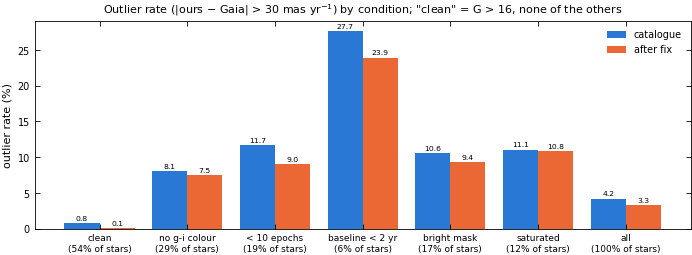

In [3]:
# 2. Outlier rate per condition, catalogue vs after the fix
conds = [('clean', clean), ('no g-i colour', nocol), ('< 10 epochs', H['n_epochs'] < 10), ('baseline < 2 yr', H['baseline_days'] < 730),
         ('bright mask', H['flag_bright'].astype(bool)), ('saturated', H['flag_saturated'].astype(bool)), ('all', np.ones(len(H), bool))]
fig, ax = plt.subplots(figsize=(ps.PAGE, 2.6), constrained_layout=True)
xx = np.arange(len(conds))
for k, (o, label) in enumerate([(out_cat, 'catalogue'), (out_fix, 'after fix')]):
    rate = [100 * o[s].mean() for _, s in conds]
    ax.bar(xx + 0.2 * (2 * k - 1), rate, width=0.4, color=ps.SERIES[k], label=label)
    for x, r in zip(xx, rate):
        ax.text(x + 0.2 * (2 * k - 1), r + 0.4, f'{r:.1f}', ha='center', fontsize=5.5)
ax.set_xticks(xx, [f'{n}\n({100 * s.mean():.0f}% of stars)' for n, s in conds], fontsize=6.5)
ax.set_ylabel('outlier rate (%)'); ax.legend()
ax.set_title('Outlier rate (|ours $-$ Gaia| > 30 mas yr$^{-1}$) by condition; "clean" = G > 16, none of the others')
plt.savefig(OUT + 'h1_rate_by_condition.pdf')

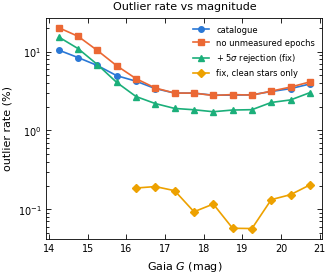

In [4]:
# 3. Outlier rate vs G: catalogue / without unmeasured epochs / after the fix; and clean stars only
gb = np.arange(14, 21.01, 0.5); gc = 0.5 * (gb[1:] + gb[:-1])
fig, ax = plt.subplots(figsize=(ps.COLUMN, 2.8), constrained_layout=True)
for k, (o, label) in enumerate([(out_cat, 'catalogue'), (dpm_refit > 30, 'no unmeasured epochs'), (out_fix, '+ 5$\\sigma$ rejection (fix)'),
                                (out_fix & clean, 'fix, clean stars only')]):
    sel = clean if 'clean' in label else np.ones(len(H), bool)
    rate = [100 * o[sel & (G > a) & (G <= b)].mean() if (sel & (G > a) & (G <= b)).sum() > 50 else np.nan for a, b in zip(gb, gb[1:])]
    ax.plot(gc, rate, marker=ps.MARKERS[k], color=ps.SERIES[k], label=label)
ax.set_yscale('log'); ax.set_xlabel('Gaia $G$ (mag)'); ax.set_ylabel('outlier rate (%)')
ax.legend(fontsize=6); ax.set_title('Outlier rate vs magnitude')
plt.savefig(OUT + 'h1_rate_vs_G.pdf')

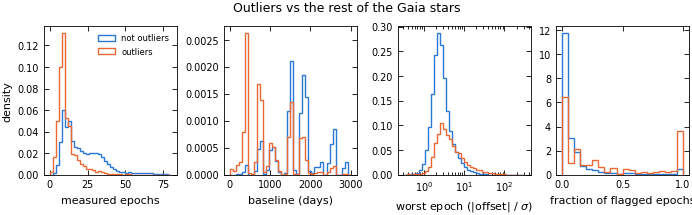

In [5]:
# 4. Outliers vs the rest: epochs, baseline, worst epoch, flagged epochs
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.2), constrained_layout=True)
for ax, col, bins, xlabel in [(axes[0], 'n_valid', np.arange(0, 81, 2), 'measured epochs'),
                              (axes[1], 'baseline_days', np.linspace(0, 3000, 41), 'baseline (days)'),
                              (axes[2], 'chi_max', np.logspace(-0.5, 2.5, 41), 'worst epoch (|offset| / $\\sigma$)'),
                              (axes[3], 'frac_dqmask', np.linspace(0, 1, 21), 'fraction of flagged epochs')]:
    for k, (s, label) in enumerate([(~out_cat, 'not outliers'), (out_cat, 'outliers')]):
        v = H[col][s]; v = v[np.isfinite(v)]
        ax.hist(v, bins=bins, density=True, histtype='step', color=ps.SERIES[k], label=label)
    ax.set_xlabel(xlabel)
    if col == 'chi_max': ax.set_xscale('log')
axes[0].set_ylabel('density'); axes[0].legend(fontsize=6)
fig.suptitle('Outliers vs the rest of the Gaia stars')
plt.savefig(OUT + 'h1_epoch_properties.pdf')

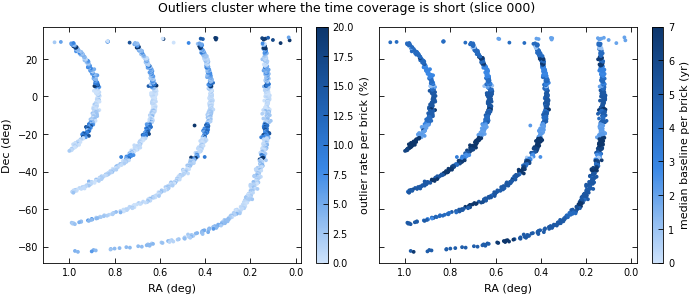

In [6]:
# 5. Where on the sky: outlier rate per brick
b = np.char.strip(H['brickname'].astype(str)); ub, inv = np.unique(b, return_inverse=True)
n = np.bincount(inv); rate = np.bincount(inv, out_cat.astype(float)) / n
ra = np.bincount(inv, H['ra']) / n; dec = np.bincount(inv, H['dec']) / n
base = np.array([np.median(H['baseline_days'][inv == j]) for j in range(len(ub))]) / 365.25
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 3.0), sharey=True, constrained_layout=True)
for ax, c, lab, cm, lim in [(axes[0], 100 * rate, 'outlier rate per brick (%)', ps.SEQUENTIAL, (0, 20)),
                            (axes[1], base, 'median baseline per brick (yr)', ps.SEQUENTIAL, (0, 7))]:
    sc = ax.scatter(ra, dec, c=c, s=3, cmap=cm, vmin=lim[0], vmax=lim[1], rasterized=True)
    ax.set_xlabel('RA (deg)'); ax.invert_xaxis(); plt.colorbar(sc, ax=ax, label=lab)
axes[0].set_ylabel('Dec (deg)')
fig.suptitle('Outliers cluster where the time coverage is short (slice 000)')
plt.savefig(OUT + 'h1_sky.png', dpi=200)